In [11]:
#检查单细胞的TAD在哪个窗口
import collections

# 设置窗口大小
window_size = 500000
cell_file = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/2-10-1.strength.txt"  # 需要检查的细胞文件

# 存储窗口信息的字典，键是 (染色体, window_start)，值是一个列表，存储TAD的 (start, end, strength)
window_tads = collections.defaultdict(list)

# 读取文件
with open(cell_file, "r") as f:
    for line in f:
        chrom, start, end, _, strength = line.strip().split()
        start, end = int(start), int(end)
        
        # 计算窗口起始位置
        window_start = (start // window_size) * window_size
        
        # 存储到窗口字典中
        window_tads[(chrom, window_start)].append((start, end, strength))

# 打印结果
for (chrom, window_start), tads in sorted(window_tads.items()):
    print(f"染色体 {chrom}, 窗口 {window_start}-{window_start + window_size}:")
    for tad in tads:
        print(f"  TAD: start={tad[0]}, end={tad[1]}, strength={tad[2]}")
    print()


染色体 1, 窗口 500000-1000000:
  TAD: start=680000, end=1400000, strength=-0.016319073895324825

染色体 1, 窗口 1000000-1500000:
  TAD: start=1400000, end=1720000, strength=1.0861198509669612

染色体 1, 窗口 1500000-2000000:
  TAD: start=1720000, end=2120000, strength=-0.48792962577254073

染色体 1, 窗口 2000000-2500000:
  TAD: start=2160000, end=2280000, strength=1.6400584016411752
  TAD: start=2320000, end=2720000, strength=4.240093577327848

染色体 1, 窗口 2500000-3000000:
  TAD: start=2720000, end=2960000, strength=6.978874079180597

染色体 1, 窗口 3000000-3500000:
  TAD: start=3000000, end=3680000, strength=3.762159030233312

染色体 1, 窗口 3500000-4000000:
  TAD: start=3760000, end=4640000, strength=0.2608745845052487

染色体 1, 窗口 4500000-5000000:
  TAD: start=4640000, end=6040000, strength=2.1486412311434853

染色体 1, 窗口 6000000-6500000:
  TAD: start=6040000, end=6640000, strength=2.167243521540875

染色体 1, 窗口 6500000-7000000:
  TAD: start=6640000, end=7520000, strength=-0.26263250469072724

染色体 1, 窗口 7500000-8000000:

  TAD: start=22160000, end=22800000, strength=0.39389295404907193

染色体 11, 窗口 22500000-23000000:
  TAD: start=22800000, end=23600000, strength=1.5974908768463891

染色体 11, 窗口 23500000-24000000:
  TAD: start=23600000, end=24680000, strength=0.28637796218024814

染色体 11, 窗口 24500000-25000000:
  TAD: start=24680000, end=24760000, strength=2.496542094568327
  TAD: start=24800000, end=25240000, strength=0.8731425133117796

染色体 11, 窗口 25000000-25500000:
  TAD: start=25240000, end=25880000, strength=5.022373305714133

染色体 11, 窗口 25500000-26000000:
  TAD: start=25880000, end=26080000, strength=-0.4864136164393933

染色体 11, 窗口 26000000-26500000:
  TAD: start=26120000, end=26440000, strength=2.0587048457777817
  TAD: start=26480000, end=27080000, strength=1.354886231046676

染色体 11, 窗口 27000000-27500000:
  TAD: start=27080000, end=27800000, strength=0.8671618238411476

染色体 11, 窗口 27500000-28000000:
  TAD: start=27800000, end=28520000, strength=1.0280067789309524

染色体 11, 窗口 28500000-29000000:
  TAD:

  TAD: start=32080000, end=33040000, strength=-1.5318205500075053

染色体 17, 窗口 33000000-33500000:
  TAD: start=33040000, end=33200000, strength=0.2849212920762406
  TAD: start=33200000, end=33720000, strength=inf

染色体 17, 窗口 33500000-34000000:
  TAD: start=33720000, end=33880000, strength=4.565202203471712
  TAD: start=33880000, end=34520000, strength=8.716078481108134

染色体 17, 窗口 34500000-35000000:
  TAD: start=34520000, end=35440000, strength=0.499995628279962

染色体 17, 窗口 35000000-35500000:
  TAD: start=35440000, end=35880000, strength=2.041390738761871

染色体 17, 窗口 35500000-36000000:
  TAD: start=35880000, end=36680000, strength=0.974440225725

染色体 17, 窗口 36500000-37000000:
  TAD: start=36680000, end=37640000, strength=2.7006122984896757

染色体 17, 窗口 37500000-38000000:
  TAD: start=37640000, end=38280000, strength=3.020289831563634

染色体 17, 窗口 38000000-38500000:
  TAD: start=38280000, end=38760000, strength=0.9929097747053434

染色体 17, 窗口 38500000-39000000:
  TAD: start=38760000, end=39

In [12]:
#批量处理 PA 500k 作为窗口大小
import os
import numpy as np

# 定义窗口大小，例如设定每个窗口的大小为500000
window_size = 500000

# 指定文件路径
directory = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength'

# 获取所有文件
files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 存储所有细胞的TAD数据
tad_data = {}

# 读取每个文件的数据
for file in files:
    # 提取细胞ID作为列名，去掉扩展名
    cell_id = file.split('.')[0]
    tad_data[cell_id] = []

    # 构造文件的完整路径
    file_path = os.path.join(directory, file)

    # 读取文件并处理
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            # 解析每行数据
            parts = line.strip().split('\t')
            chr_name, start, end, _, strength = parts[0], int(parts[1]), int(parts[2]), parts[3], parts[4]

            # 如果 strength 是 'nan' 或 'inf'，则跳过
            if strength == 'nan' or strength == 'inf':
                continue

            strength = float(strength)

            # 计算该TAD所在的窗口编号
            window_start = (start // window_size) * window_size
            window_end = window_start + window_size

            # 如果该窗口已经存在，则累加到该窗口的TAD列表中
            if len(tad_data[cell_id]) == 0 or tad_data[cell_id][-1][0] != window_start or tad_data[cell_id][-1][2] != chr_name:
                tad_data[cell_id].append([chr_name, window_start, window_end, strength])
            else:
                tad_data[cell_id][-1][3] += strength

# 转化为矩阵
# 获取所有窗口的起始位置，按染色体和起始位置进行排序
windows = sorted(set((window[0], window[1], window[2]) for data in tad_data.values() for window in data))

# 创建矩阵，每列是细胞，每行是一个窗口
matrix = np.zeros((len(windows), len(files)))
window_ids = []

# 填充矩阵
for col, file in enumerate(files):
    cell_id = file.split('.')[0]  # 确保这里使用去掉扩展名的cell_id
    for row, (chr_name, window_start, window_end) in enumerate(windows):
        # 计算该窗口的平均strength
        total_strength = 0
        count = 0
        for data in tad_data[cell_id]:
            if data[0] == chr_name and data[1] == window_start and data[2] == window_end:
                total_strength += data[3]
                count += 1
        if count > 0:
            matrix[row, col] = total_strength / count
        else:
            matrix[row, col] = np.nan
        
        # 添加窗口的ID (chr_name-start-end)
        if row >= len(window_ids):
            window_ids.append(f"{chr_name}-{window_start}-{window_end}")

# 输出矩阵到文件
output_file = os.path.join(directory, 'PA_TADstrength_matrix.txt')

# 组合矩阵数据与窗口 ID
header = '\t'.join(['WindowID'] + [f.split('.')[0] for f in files])

# 使用np.savetxt写入矩阵
with open(output_file, 'w') as f:
    f.write(header + '\n')
    for i, window_id in enumerate(window_ids):
        row_data = [window_id] + list(map(str, matrix[i]))
        f.write('\t'.join(row_data) + '\n')

print(f"矩阵已保存至: {output_file}")


矩阵已保存至: /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix.txt


In [86]:
#批量处理 PA 250k 作为窗口大小
import os
import numpy as np

# 定义窗口大小，例如设定每个窗口的大小为 250000
window_size = 250000

# 指定文件路径
directory = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength'

# 获取所有文件
files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 存储所有细胞的TAD数据
tad_data = {}

# 读取每个文件的数据
for file in files:
    # 提取细胞ID作为列名，去掉扩展名
    cell_id = file.split('.')[0]
    tad_data[cell_id] = []

    # 构造文件的完整路径
    file_path = os.path.join(directory, file)

    # 读取文件并处理
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            # 解析每行数据
            parts = line.strip().split('\t')
            chr_name, start, end, _, strength = parts[0], int(parts[1]), int(parts[2]), parts[3], parts[4]

            # 如果 strength 是 'nan' 或 'inf'，则跳过
            if strength == 'nan' or strength == 'inf':
                continue

            strength = float(strength)

            # 计算该TAD所在的窗口编号
            window_start = (start // window_size) * window_size
            window_end = window_start + window_size

            # 如果该窗口已经存在，则累加到该窗口的TAD列表中
            if len(tad_data[cell_id]) == 0 or tad_data[cell_id][-1][0] != window_start or tad_data[cell_id][-1][2] != chr_name:
                tad_data[cell_id].append([chr_name, window_start, window_end, strength])
            else:
                tad_data[cell_id][-1][3] += strength

# 转化为矩阵
# 获取所有窗口的起始位置，按染色体和起始位置进行排序
windows = sorted(set((window[0], window[1], window[2]) for data in tad_data.values() for window in data))

# 创建矩阵，每列是细胞，每行是一个窗口
matrix = np.zeros((len(windows), len(files)))
window_ids = []

# 填充矩阵
for col, file in enumerate(files):
    cell_id = file.split('.')[0]  # 确保这里使用去掉扩展名的cell_id
    for row, (chr_name, window_start, window_end) in enumerate(windows):
        # 计算该窗口的平均strength
        total_strength = 0
        count = 0
        for data in tad_data[cell_id]:
            if data[0] == chr_name and data[1] == window_start and data[2] == window_end:
                total_strength += data[3]
                count += 1
        if count > 0:
            matrix[row, col] = total_strength / count
        else:
            matrix[row, col] = np.nan
        
        # 添加窗口的ID (chr_name-start-end)
        if row >= len(window_ids):
            window_ids.append(f"{chr_name}-{window_start}-{window_end}")

# 输出矩阵到文件
output_file = os.path.join(directory, 'PA_TADstrength_matrix_w250k.txt')

# 组合矩阵数据与窗口 ID
header = '\t'.join(['WindowID'] + [f.split('.')[0] for f in files])

# 使用np.savetxt写入矩阵
with open(output_file, 'w') as f:
    f.write(header + '\n')
    for i, window_id in enumerate(window_ids):
        row_data = [window_id] + list(map(str, matrix[i]))
        f.write('\t'.join(row_data) + '\n')

print(f"矩阵已保存至: {output_file}")


矩阵已保存至: /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix_w250k.txt


In [101]:
#批量处理 PA 1m 作为窗口大小
import os
import numpy as np

# 定义窗口大小，例如设定每个窗口的大小为 1000000
window_size = 1000000

# 指定文件路径
directory = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength'

# 获取所有文件
files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 存储所有细胞的TAD数据
tad_data = {}

# 读取每个文件的数据
for file in files:
    # 提取细胞ID作为列名，去掉扩展名
    cell_id = file.split('.')[0]
    tad_data[cell_id] = []

    # 构造文件的完整路径
    file_path = os.path.join(directory, file)

    # 读取文件并处理
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            # 解析每行数据
            parts = line.strip().split('\t')
            chr_name, start, end, _, strength = parts[0], int(parts[1]), int(parts[2]), parts[3], parts[4]

            # 如果 strength 是 'nan' 或 'inf'，则跳过
            if strength == 'nan' or strength == 'inf':
                continue

            strength = float(strength)

            # 计算该TAD所在的窗口编号
            window_start = (start // window_size) * window_size
            window_end = window_start + window_size

            # 如果该窗口已经存在，则累加到该窗口的TAD列表中
            if len(tad_data[cell_id]) == 0 or tad_data[cell_id][-1][0] != window_start or tad_data[cell_id][-1][2] != chr_name:
                tad_data[cell_id].append([chr_name, window_start, window_end, strength])
            else:
                tad_data[cell_id][-1][3] += strength

# 转化为矩阵
# 获取所有窗口的起始位置，按染色体和起始位置进行排序
windows = sorted(set((window[0], window[1], window[2]) for data in tad_data.values() for window in data))

# 创建矩阵，每列是细胞，每行是一个窗口
matrix = np.zeros((len(windows), len(files)))
window_ids = []

# 填充矩阵
for col, file in enumerate(files):
    cell_id = file.split('.')[0]  # 确保这里使用去掉扩展名的cell_id
    for row, (chr_name, window_start, window_end) in enumerate(windows):
        # 计算该窗口的平均strength
        total_strength = 0
        count = 0
        for data in tad_data[cell_id]:
            if data[0] == chr_name and data[1] == window_start and data[2] == window_end:
                total_strength += data[3]
                count += 1
        if count > 0:
            matrix[row, col] = total_strength / count
        else:
            matrix[row, col] = np.nan
        
        # 添加窗口的ID (chr_name-start-end)
        if row >= len(window_ids):
            window_ids.append(f"{chr_name}-{window_start}-{window_end}")

# 输出矩阵到文件
output_file = os.path.join(directory, 'PA_TADstrength_matrix_w1m.txt')

# 组合矩阵数据与窗口 ID
header = '\t'.join(['WindowID'] + [f.split('.')[0] for f in files])

# 使用np.savetxt写入矩阵
with open(output_file, 'w') as f:
    f.write(header + '\n')
    for i, window_id in enumerate(window_ids):
        row_data = [window_id] + list(map(str, matrix[i]))
        f.write('\t'.join(row_data) + '\n')

print(f"矩阵已保存至: {output_file}")


矩阵已保存至: /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix_w1m.txt


In [102]:
#提取表达量矩阵，因为有些细胞并不在拟时序分析列表中
import pandas as pd

# 读取表达量矩阵文件
expression_matrix_file = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix_w1m.txt'  # 替换成你的表达量矩阵文件名
expression_matrix = pd.read_csv(expression_matrix_file, sep='\t')

# 读取细胞ID文件
cell_ids_file = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/pa_id.txt'  # 替换成你的细胞ID文件名
with open(cell_ids_file, 'r') as f:
    cell_ids = f.read().splitlines()

# 提取包含在细胞ID文件中的细胞的表达量矩阵
filtered_expression_matrix = expression_matrix[['WindowID'] + cell_ids]

# 保存提取后的表达量矩阵到新的文件
filtered_expression_matrix_file = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix_w1m_new.txt'  # 输出文件名
filtered_expression_matrix.to_csv(filtered_expression_matrix_file, sep='\t', index=False)

print(f"提取后的表达量矩阵已保存到 {filtered_expression_matrix_file}")


提取后的表达量矩阵已保存到 /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix_w1m_new.txt


In [13]:
#批量处理 IVF 500k 作为窗口大小
import os
import numpy as np

# 定义窗口大小，例如设定每个窗口的大小为500000
window_size = 500000

# 指定文件路径
directory = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength'

# 获取所有文件
files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 存储所有细胞的TAD数据
tad_data = {}

# 读取每个文件的数据
for file in files:
    # 提取细胞ID作为列名，去掉扩展名
    cell_id = file.split('.')[0]
    tad_data[cell_id] = []

    # 构造文件的完整路径
    file_path = os.path.join(directory, file)

    # 读取文件并处理
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            # 解析每行数据
            parts = line.strip().split('\t')
            chr_name, start, end, _, strength = parts[0], int(parts[1]), int(parts[2]), parts[3], parts[4]

            # 如果 strength 是 'nan' 或 'inf'，则跳过
            if strength == 'nan' or strength == 'inf':
                continue

            strength = float(strength)

            # 计算该TAD所在的窗口编号
            window_start = (start // window_size) * window_size
            window_end = window_start + window_size

            # 如果该窗口已经存在，则累加到该窗口的TAD列表中
            if len(tad_data[cell_id]) == 0 or tad_data[cell_id][-1][0] != window_start or tad_data[cell_id][-1][2] != chr_name:
                tad_data[cell_id].append([chr_name, window_start, window_end, strength])
            else:
                tad_data[cell_id][-1][3] += strength

# 转化为矩阵
# 获取所有窗口的起始位置，按染色体和起始位置进行排序
windows = sorted(set((window[0], window[1], window[2]) for data in tad_data.values() for window in data))

# 创建矩阵，每列是细胞，每行是一个窗口
matrix = np.zeros((len(windows), len(files)))
window_ids = []

# 填充矩阵
for col, file in enumerate(files):
    cell_id = file.split('.')[0]  # 确保这里使用去掉扩展名的cell_id
    for row, (chr_name, window_start, window_end) in enumerate(windows):
        # 计算该窗口的平均strength
        total_strength = 0
        count = 0
        for data in tad_data[cell_id]:
            if data[0] == chr_name and data[1] == window_start and data[2] == window_end:
                total_strength += data[3]
                count += 1
        if count > 0:
            matrix[row, col] = total_strength / count
        else:
            matrix[row, col] = np.nan
        
        # 添加窗口的ID (chr_name-start-end)
        if row >= len(window_ids):
            window_ids.append(f"{chr_name}-{window_start}-{window_end}")

# 输出矩阵到文件
output_file = os.path.join(directory, 'IVF_TADstrength_matrix.txt')

# 组合矩阵数据与窗口 ID
header = '\t'.join(['WindowID'] + [f.split('.')[0] for f in files])

# 使用np.savetxt写入矩阵
with open(output_file, 'w') as f:
    f.write(header + '\n')
    for i, window_id in enumerate(window_ids):
        row_data = [window_id] + list(map(str, matrix[i]))
        f.write('\t'.join(row_data) + '\n')

print(f"矩阵已保存至: {output_file}")


矩阵已保存至: /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix.txt


In [87]:
#批量处理 IVF 250k 作为窗口大小
import os
import numpy as np

# 定义窗口大小，例如设定每个窗口的大小为250000
window_size = 250000

# 指定文件路径
directory = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength'

# 获取所有文件
files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 存储所有细胞的TAD数据
tad_data = {}

# 读取每个文件的数据
for file in files:
    # 提取细胞ID作为列名，去掉扩展名
    cell_id = file.split('.')[0]
    tad_data[cell_id] = []

    # 构造文件的完整路径
    file_path = os.path.join(directory, file)

    # 读取文件并处理
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            # 解析每行数据
            parts = line.strip().split('\t')
            chr_name, start, end, _, strength = parts[0], int(parts[1]), int(parts[2]), parts[3], parts[4]

            # 如果 strength 是 'nan' 或 'inf'，则跳过
            if strength == 'nan' or strength == 'inf':
                continue

            strength = float(strength)

            # 计算该TAD所在的窗口编号
            window_start = (start // window_size) * window_size
            window_end = window_start + window_size

            # 如果该窗口已经存在，则累加到该窗口的TAD列表中
            if len(tad_data[cell_id]) == 0 or tad_data[cell_id][-1][0] != window_start or tad_data[cell_id][-1][2] != chr_name:
                tad_data[cell_id].append([chr_name, window_start, window_end, strength])
            else:
                tad_data[cell_id][-1][3] += strength

# 转化为矩阵
# 获取所有窗口的起始位置，按染色体和起始位置进行排序
windows = sorted(set((window[0], window[1], window[2]) for data in tad_data.values() for window in data))

# 创建矩阵，每列是细胞，每行是一个窗口
matrix = np.zeros((len(windows), len(files)))
window_ids = []

# 填充矩阵
for col, file in enumerate(files):
    cell_id = file.split('.')[0]  # 确保这里使用去掉扩展名的cell_id
    for row, (chr_name, window_start, window_end) in enumerate(windows):
        # 计算该窗口的平均strength
        total_strength = 0
        count = 0
        for data in tad_data[cell_id]:
            if data[0] == chr_name and data[1] == window_start and data[2] == window_end:
                total_strength += data[3]
                count += 1
        if count > 0:
            matrix[row, col] = total_strength / count
        else:
            matrix[row, col] = np.nan
        
        # 添加窗口的ID (chr_name-start-end)
        if row >= len(window_ids):
            window_ids.append(f"{chr_name}-{window_start}-{window_end}")

# 输出矩阵到文件
output_file = os.path.join(directory, 'IVF_TADstrength_matrix_w250k.txt')

# 组合矩阵数据与窗口 ID
header = '\t'.join(['WindowID'] + [f.split('.')[0] for f in files])

# 使用np.savetxt写入矩阵
with open(output_file, 'w') as f:
    f.write(header + '\n')
    for i, window_id in enumerate(window_ids):
        row_data = [window_id] + list(map(str, matrix[i]))
        f.write('\t'.join(row_data) + '\n')

print(f"矩阵已保存至: {output_file}")


矩阵已保存至: /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix_w250k.txt


In [103]:
#批量处理 IVF 1m 作为窗口大小
import os
import numpy as np

# 定义窗口大小，例如设定每个窗口的大小为 1000000
window_size = 1000000

# 指定文件路径
directory = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength'

# 获取所有文件
files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 存储所有细胞的TAD数据
tad_data = {}

# 读取每个文件的数据
for file in files:
    # 提取细胞ID作为列名，去掉扩展名
    cell_id = file.split('.')[0]
    tad_data[cell_id] = []

    # 构造文件的完整路径
    file_path = os.path.join(directory, file)

    # 读取文件并处理
    with open(file_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            # 解析每行数据
            parts = line.strip().split('\t')
            chr_name, start, end, _, strength = parts[0], int(parts[1]), int(parts[2]), parts[3], parts[4]

            # 如果 strength 是 'nan' 或 'inf'，则跳过
            if strength == 'nan' or strength == 'inf':
                continue

            strength = float(strength)

            # 计算该TAD所在的窗口编号
            window_start = (start // window_size) * window_size
            window_end = window_start + window_size

            # 如果该窗口已经存在，则累加到该窗口的TAD列表中
            if len(tad_data[cell_id]) == 0 or tad_data[cell_id][-1][0] != window_start or tad_data[cell_id][-1][2] != chr_name:
                tad_data[cell_id].append([chr_name, window_start, window_end, strength])
            else:
                tad_data[cell_id][-1][3] += strength

# 转化为矩阵
# 获取所有窗口的起始位置，按染色体和起始位置进行排序
windows = sorted(set((window[0], window[1], window[2]) for data in tad_data.values() for window in data))

# 创建矩阵，每列是细胞，每行是一个窗口
matrix = np.zeros((len(windows), len(files)))
window_ids = []

# 填充矩阵
for col, file in enumerate(files):
    cell_id = file.split('.')[0]  # 确保这里使用去掉扩展名的cell_id
    for row, (chr_name, window_start, window_end) in enumerate(windows):
        # 计算该窗口的平均strength
        total_strength = 0
        count = 0
        for data in tad_data[cell_id]:
            if data[0] == chr_name and data[1] == window_start and data[2] == window_end:
                total_strength += data[3]
                count += 1
        if count > 0:
            matrix[row, col] = total_strength / count
        else:
            matrix[row, col] = np.nan
        
        # 添加窗口的ID (chr_name-start-end)
        if row >= len(window_ids):
            window_ids.append(f"{chr_name}-{window_start}-{window_end}")

# 输出矩阵到文件
output_file = os.path.join(directory, 'IVF_TADstrength_matrix_w1m.txt')

# 组合矩阵数据与窗口 ID
header = '\t'.join(['WindowID'] + [f.split('.')[0] for f in files])

# 使用np.savetxt写入矩阵
with open(output_file, 'w') as f:
    f.write(header + '\n')
    for i, window_id in enumerate(window_ids):
        row_data = [window_id] + list(map(str, matrix[i]))
        f.write('\t'.join(row_data) + '\n')

print(f"矩阵已保存至: {output_file}")


矩阵已保存至: /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix_w1m.txt


In [104]:
#ivf 250k
import pandas as pd

# 读取表达量矩阵文件
expression_matrix_file = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix_w1m.txt'  # 替换成你的表达量矩阵文件名
expression_matrix = pd.read_csv(expression_matrix_file, sep='\t')

# 读取细胞ID文件
cell_ids_file = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/ivf_id.txt'  # 替换成你的细胞ID文件名
with open(cell_ids_file, 'r') as f:
    cell_ids = f.read().splitlines()

# 提取包含在细胞ID文件中的细胞的表达量矩阵
filtered_expression_matrix = expression_matrix[['WindowID'] + cell_ids]

# 保存提取后的表达量矩阵到新的文件
filtered_expression_matrix_file = '/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix_w1m_new.txt'  # 输出文件名
filtered_expression_matrix.to_csv(filtered_expression_matrix_file, sep='\t', index=False)

print(f"提取后的表达量矩阵已保存到 {filtered_expression_matrix_file}")


提取后的表达量矩阵已保存到 /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix_w1m_new.txt


In [105]:
!cp /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/IVF_strength/IVF_TADstrength_matrix_w1m_new.txt /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/
!cp /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/PA_TADstrength_matrix_w1m_new.txt /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/

In [147]:
#IVF
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

# 读取数据
tad_strength = pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/IVF_TADstrength_matrix_w1m_new.txt", sep="\t", index_col=0)
time_data = pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/ivf_time.txt", sep="\t")

# 构建时间字典
time_dict = dict(zip(time_data['id'], time_data['time']))

# 存储相关性结果
correlation_results = []
correlation_results_not_significant = []
for window_id, row in tad_strength.iterrows():
    # 筛选出有数值的细胞
    valid_cells = row.dropna().index
    
    # 如果该窗口有有效的细胞ID
    if len(valid_cells) > 0:
        # 找到有效细胞的时间值
        times = pd.Series(time_dict).loc[valid_cells].dropna()  # 确保时间数据有效
        
        # 如果至少有两个有效的细胞及其对应的时间
        if len(times) > 1:
            # 提取对应的窗口强度值
            values = row[valid_cells].loc[times.index].astype(float)  # 保证对应细胞的强度值和时间值
            
            # 确保数据中没有NaN或inf
            values = values.replace([np.inf, -np.inf], np.nan).dropna()
            times = times.replace([np.inf, -np.inf], np.nan).dropna()
            
            # 重新检查数据是否有效
            if len(values) > 1 and len(values) == len(times):
                num_valid_cells = len(values)  # 记录有效细胞数量
                
                # 计算皮尔逊和斯皮尔曼相关性
                pearson_corr, pearson_p = pearsonr(values, times)
                spearman_corr, spearman_p = spearmanr(values, times)
                
                # 仅存储 p 值显著的结果（p < 0.05）
                if pearson_p < 0.05:
                    correlation_results.append([window_id, num_valid_cells, pearson_corr, pearson_p, spearman_corr, spearman_p])
                else:
                    correlation_results_not_significant.append([window_id, num_valid_cells, pearson_corr, pearson_p, spearman_corr, spearman_p])

# 转换为 DataFrame 并按 Pearson 相关性排序
correlation_df = pd.DataFrame(correlation_results, columns=['WindowID', 'Valid_Cell_Count', 'Pearson_corr', 'Pearson_p', 'Spearman_corr', 'Spearman_p'])
correlation_df = correlation_df.sort_values(by='Pearson_corr', ascending=False)

# 输出显著性结果
print(correlation_df)
correlation_df.to_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/IVF_correlation_results_significant_w1m.txt", sep="\t", index=False)

# 转换为 DataFrame 并按 Pearson 相关性排序
not_correlation_df = pd.DataFrame(correlation_results_not_significant, columns=['WindowID', 'Valid_Cell_Count', 'Pearson_corr', 'Pearson_p', 'Spearman_corr', 'Spearman_p'])
not_correlation_df = not_correlation_df.sort_values(by='Pearson_corr', ascending=False)
not_correlation_df.to_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/IVF_correlation_results_not_significant_w1m.txt", sep="\t", index=False)


                  WindowID  Valid_Cell_Count  Pearson_corr  Pearson_p  \
126   17-61000000-62000000                74      0.347483   0.002418   
30   1-154000000-155000000               139      0.308660   0.000218   
34   1-175000000-176000000               170      0.223277   0.003425   
191    6-20000000-21000000               171      0.202190   0.008001   
181  4-122000000-123000000               174      0.193591   0.010482   
..                     ...               ...           ...        ...   
128     18-2000000-3000000                45     -0.311424   0.037306   
1      1-15000000-16000000               162     -0.319272   0.000035   
28   1-147000000-148000000               161     -0.322849   0.000030   
27   1-146000000-147000000               149     -0.325638   0.000051   
194    6-70000000-71000000               163     -0.327459   0.000020   

     Spearman_corr  Spearman_p  
126       0.035587    0.763405  
30        0.305134    0.000260  
34        0.190664    0.

In [114]:
#PA
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

# 读取数据
tad_strength = pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/PA_TADstrength_matrix_w1m_new.txt", sep="\t", index_col=0)
time_data = pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/pa_time.txt", sep="\t")

# 构建时间字典
time_dict = dict(zip(time_data['id'], time_data['time']))

# 存储相关性结果
correlation_results = []
correlation_results_not_significant = []
for window_id, row in tad_strength.iterrows():
    # 筛选出有数值的细胞
    valid_cells = row.dropna().index
    
    # 如果该窗口有有效的细胞ID
    if len(valid_cells) > 0:
        # 找到有效细胞的时间值
        times = pd.Series(time_dict).loc[valid_cells].dropna()  # 确保时间数据有效
        
        # 如果至少有两个有效的细胞及其对应的时间
        if len(times) > 1:
            # 提取对应的窗口强度值
            values = row[valid_cells].loc[times.index].astype(float)  # 保证对应细胞的强度值和时间值
            
            # 确保数据中没有NaN或inf
            values = values.replace([np.inf, -np.inf], np.nan).dropna()
            times = times.replace([np.inf, -np.inf], np.nan).dropna()
            
            # 重新检查数据是否有效
            if len(values) > 1 and len(values) == len(times):
                num_valid_cells = len(values)  # 记录有效细胞数量
                
                # 计算皮尔逊和斯皮尔曼相关性
                pearson_corr, pearson_p = pearsonr(values, times)
                spearman_corr, spearman_p = spearmanr(values, times)
                
                # 仅存储 p 值显著的结果（p < 0.05）
                if pearson_p < 0.05:
                    correlation_results.append([window_id, num_valid_cells, pearson_corr, pearson_p, spearman_corr, spearman_p])
                else:
                    correlation_results_not_significant.append([window_id, num_valid_cells, pearson_corr, pearson_p, spearman_corr, spearman_p])

# 转换为 DataFrame 并按 Pearson 相关性排序
correlation_df = pd.DataFrame(correlation_results, columns=['WindowID', 'Valid_Cell_Count', 'Pearson_corr', 'Pearson_p', 'Spearman_corr', 'Spearman_p'])
correlation_df = correlation_df.sort_values(by='Pearson_corr', ascending=False)

# 输出显著性结果
print(correlation_df)
correlation_df.to_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/PA_correlation_results_significant_w1m.txt", sep="\t", index=False)


                 WindowID  Valid_Cell_Count  Pearson_corr  Pearson_p  \
13    4-76000000-77000000               150      0.190095   0.019806   
6    13-31000000-32000000               141     -0.169951   0.043928   
11    3-64000000-65000000               124     -0.177856   0.048126   
4   1-203000000-204000000               127     -0.184473   0.037875   
15    5-28000000-29000000               129     -0.186781   0.034051   
5   1-249000000-250000000               111     -0.191003   0.044634   
12    3-69000000-70000000               136     -0.199470   0.019903   
9      18-2000000-3000000               114     -0.203094   0.030220   
16      7-6000000-7000000               120     -0.222904   0.014401   
3   1-166000000-167000000               131     -0.223518   0.010278   
2   1-159000000-160000000               120     -0.227447   0.012479   
14    4-92000000-93000000               134     -0.232071   0.006972   
8     14-9000000-10000000               116     -0.238023   0.01

In [59]:
cd /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time

/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time


选择了 Mann-Whitney U 检验。
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

positive vs. negative: Mann-Whitney-Wilcoxon test two-sided, P_val:9.511e-02 U_stat=2.108e+03


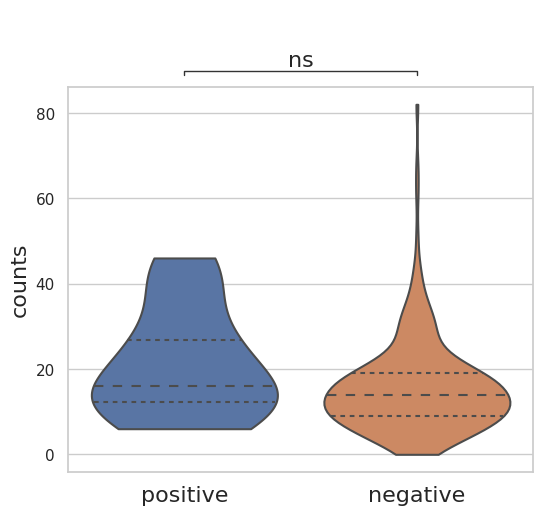

In [146]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from statannotations.Annotator import Annotator


# 读取数据
data = pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/pos_vs_neg_gene_density.txt", sep="\t")  

# 画图
plt.figure(figsize=(6, 5))
ax = sns.violinplot(x="type", y="counts", data=data, inner="quart", cut=0, scale="width")

# 进行统计检验（t 检验）
white_values = data[data["type"] == "positive"]["counts"]
beige_values = data[data["type"] == "negative"]["counts"]

chosen_test = 'Mann-Whitney'
# 对数据进行检验
pairs = [('positive', 'negative')]
annotator = Annotator(ax, pairs, data=data, x="type", y="counts", order=['positive', 'negative'])

if chosen_test == 't-test_ind':
    annotator.configure(test='t-test_ind', text_format='star', line_height=0.01, line_width=1, loc='outside',fontsize=16)
    print("选择了 t-检验 (独立样本 t 检验)。")
elif chosen_test == 't-test_welch':
    annotator.configure(test='t-test_welch', text_format='star', line_height=0.01, line_width=1, loc='outside',fontsize=16)
    print("选择了 Welch's t-检验。")
else:
    annotator.configure(test='Mann-Whitney', text_format='star', line_height=0.01, line_width=1, loc='outside',fontsize=16)
    print("选择了 Mann-Whitney U 检验。")

annotator.apply_and_annotate()

# 添加标题
plt.title(" ",fontsize=20,pad=40)
plt.ylabel('counts',fontsize=16)
plt.xlabel('')
plt.xticks(ticks=[0, 1], labels=["positive", "negative"], fontsize=16)
#plt.legend(title="Cell Type", fontsize=12)
plt.show()

选择了 Mann-Whitney U 检验。
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

positive vs. ns: Mann-Whitney-Wilcoxon test two-sided, P_val:2.292e-02 U_stat=1.060e+04


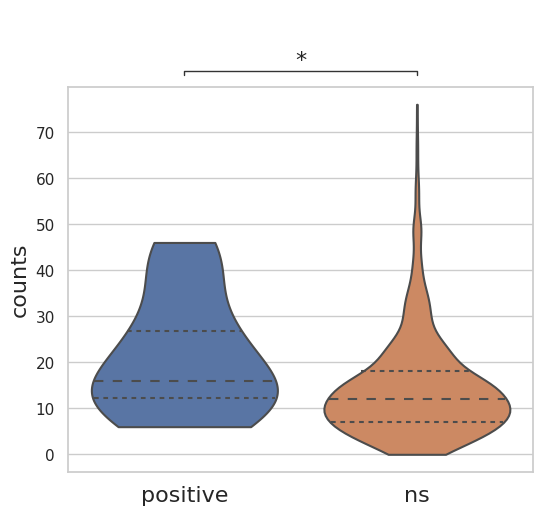

In [149]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
from statannotations.Annotator import Annotator


# 读取数据
data = pd.read_csv("/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/pos_vs_ns_gene_density.txt", sep="\t")  

# 画图
plt.figure(figsize=(6, 5))
ax = sns.violinplot(x="type", y="counts", data=data, inner="quart", cut=0, scale="width")

# 进行统计检验（t 检验）
white_values = data[data["type"] == "positive"]["counts"]
beige_values = data[data["type"] == "ns"]["counts"]

chosen_test = 'Mann-Whitney'
# 对数据进行检验
pairs = [('positive', 'ns')]
annotator = Annotator(ax, pairs, data=data, x="type", y="counts", order=['positive', 'ns'])

if chosen_test == 't-test_ind':
    annotator.configure(test='t-test_ind', text_format='star', line_height=0.01, line_width=1, loc='outside',fontsize=16)
    print("选择了 t-检验 (独立样本 t 检验)。")
elif chosen_test == 't-test_welch':
    annotator.configure(test='t-test_welch', text_format='star', line_height=0.01, line_width=1, loc='outside',fontsize=16)
    print("选择了 Welch's t-检验。")
else:
    annotator.configure(test='Mann-Whitney', text_format='star', line_height=0.01, line_width=1, loc='outside',fontsize=16)
    print("选择了 Mann-Whitney U 检验。")

annotator.apply_and_annotate()

# 添加标题
plt.title(" ",fontsize=20,pad=40)
plt.ylabel('counts',fontsize=16)
plt.xlabel('')
plt.xticks(ticks=[0, 1], labels=["positive", "ns"], fontsize=16)
#plt.legend(title="Cell Type", fontsize=12)
plt.show()

In [ ]:
import os
import pandas as pd

# 读取基因区间信息
gene_df = pd.read_csv("/home/lihaoxing/Sus_scrofa.Sscrofa11.1.110/pig_promoter.bed", sep="\t", header=None, names=["chr", "start", "end", "gene_id"])

# 指定TAD文件路径
directory = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength"
strength_files = [f for f in os.listdir(directory) if f.endswith('.strength.txt')]

# 初始化存储字典
gene_tad_data = {}

for file in strength_files:
    cell_name = file.replace(".strength.txt", "")
    
    # 读取TAD strength 文件
    tad_df = pd.read_csv(os.path.join(directory, file), sep="\t", header=None, names=["chr", "start", "end", "id", "strength"], na_values="nan")
    
    # 为当前细胞初始化TAD值列表
    gene_values = []

    for _, gene in gene_df.iterrows():
        tad = tad_df[(tad_df["chr"] == gene["chr"]) & (tad_df["start"] <= gene["start"]) & (tad_df["end"] >= gene["end"])]
        gene_values.append(tad.iloc[0]["strength"] if not tad.empty else None)
    
    # 存入字典
    gene_tad_data[cell_name] = gene_values

# 创建DataFrame，一次性插入所有细胞数据
gene_tad_matrix = pd.DataFrame(gene_tad_data, index=gene_df["gene_id"])

# 保存结果
output_path = "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/PA_strength/gene_tad_matrix.txt"
gene_tad_matrix.to_csv(output_path, sep="\t")

print(f"文件已保存至: {output_path}")



[ZGA] 列联表：
                    ZGA  非 ZGA
TAD strength 升高区域   890   3568
其他区域               2442  13388
优势比 (OR) = 1.368
P 值        = 1.431e-12

[DPA] 列联表：
                    DPA  非 DPA
TAD strength 升高区域   559   3899
其他区域               1441  14389
优势比 (OR) = 1.432
P 值        = 3.773e-11


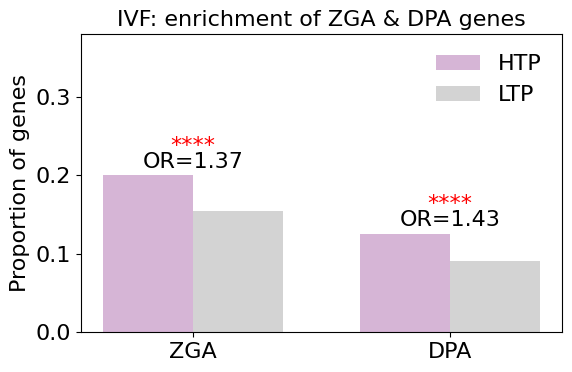

In [9]:
#IVF C0,ZGA,DPA
# =========================================================
# IVF C0：ZGA / DPA 基因在 TAD strength 随拟时序升高区域中的富集分析
# ---------------------------------------------------------
# 本脚本用于检验：
#   ZGA 基因和发育潜能相关基因（DPA）
# 是否在 TAD strength 随拟时序增加的区域（IVF C0 cluster）
# 中显著富集，相对于其他所有区域。
#
# 富集分析采用 Fisher 精确检验，
# 并通过柱状图展示目标区域与其他区域中
# ZGA / DPA 基因所占比例的差异。
# =========================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16
})

# ===============================
# 1. 基础函数
# ===============================

def read_gene_list(path):
    """
    读取基因列表文件，返回基因 ID 的集合（set）。

    假设：
    - 每行包含一个基因 ID（或第一列为基因 ID）
    - 使用 set 以保证基因唯一性，并便于集合运算
    """
    genes = []
    with open(path) as f:
        for line in f:
            if line.strip():
                genes.append(line.strip().split()[0])
    return set(genes)


def build_contingency_table(target_genes, other_genes, gene_set):
    """
    构建 Fisher 精确检验所需的 2×2 列联表：

                         gene_set    非 gene_set
    target_genes            a            b
    other_genes             c            d

    其中：
    - target_genes：位于 TAD strength 随拟时序升高区域中的基因
    - other_genes ：位于其余所有区域中的基因
    - gene_set    ：待检验的基因集合（ZGA 或 DPA）
    """
    a = len(target_genes & gene_set)
    b = len(target_genes) - a
    c = len(other_genes & gene_set)
    d = len(other_genes) - c

    table = [[a, b],
             [c, d]]
    return table


def enrichment_stats(target_genes, other_genes, gene_set):
    """
    对给定基因集合（ZGA 或 DPA）计算富集统计量，包括：

    - Fisher 精确检验的优势比（odds ratio）
    - Fisher 精确检验的 p 值
    - gene_set 在目标区域中的比例
    - gene_set 在其他区域中的比例
    """
    table = build_contingency_table(target_genes, other_genes, gene_set)
    or_value, p_value = fisher_exact(table)

    # 目标区域中 gene_set 的比例
    target_prop = table[0][0] / sum(table[0])
    # 其他区域中 gene_set 的比例
    other_prop = table[1][0] / sum(table[1])

    return table, or_value, p_value, target_prop, other_prop


# ===============================
# 2. 读取基因集合
# ===============================

# ZGA 基因列表
ZGA_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/IVF_majorZGAid.txt"
)

# DPA（发育潜能相关）基因列表
DPA_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/IVF_118_gene_cors_pos_2000.txt"
)

# IVF 中 TAD strength 随拟时序升高（C0 cluster）区域对应的基因
target_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_cluster_0_genes.new.txt"
)

# IVF 中其余区域对应的基因
other_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/IVF_cluster_0_genes.non.txt"
)

# 确保目标区域与其他区域的基因集合不重叠
assert len(target_genes & other_genes) == 0


# ===============================
# 3. 富集分析计算
# ===============================

# 待分析的基因集合
gene_sets = {
    "ZGA": ZGA_genes,
    "DPA": DPA_genes
}

results = {}

for label, geneset in gene_sets.items():
    table, or_value, p_value, tp, op = enrichment_stats(
        target_genes, other_genes, geneset
    )
    results[label] = {
        "table": table,
        "odds_ratio": or_value,
        "p_value": p_value,
        "target_prop": tp,
        "other_prop": op
    }

    # 打印列联表和统计结果，便于复现与审查
    print(f"\n[{label}] 列联表：")
    print(pd.DataFrame(
        table,
        index=["TAD strength 升高区域", "其他区域"],
        columns=[label, f"非 {label}"]
    ))
    print(f"优势比 (OR) = {or_value:.3f}")
    print(f"P 值        = {p_value:.3e}")


# ===============================
# 4. 绘制柱状图（升级为 OR 风格）
# ===============================

labels = list(results.keys())
target_props = [results[l]["target_prop"] for l in labels]
other_props = [results[l]["other_prop"] for l in labels]
p_values = [results[l]["p_value"] for l in labels]
or_values = [results[l]["odds_ratio"] for l in labels]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(6, 4))

# IVF target 区域
plt.bar(
    x - width / 2,
    target_props,
    width,
    label="HTP",
    color="#d6b5d6"
)

# IVF background
plt.bar(
    x + width / 2,
    other_props,
    width,
    label="LTP",
    color="lightgrey"
)

plt.ylabel("Proportion of genes")
plt.title("IVF: enrichment of ZGA & DPA genes")
plt.xticks(x, labels)

plt.ylim(0, max(target_props + other_props) * 1.9)


# ===== 核心：OR + 显著性 =====
for i in range(len(labels)):
    y = max(target_props[i], other_props[i])

    # OR（主信息）
    plt.text(
        i,
        y + 0.01,
        f"OR={or_values[i]:.2f}",
        ha="center",
        fontsize=16
    )

    # 显著性星号
    p = p_values[i]
    if p <= 0.05:
        if p <= 1e-4:
            star = "****"
        elif p <= 1e-3:
            star = "***"
        elif p <= 1e-2:
            star = "**"
        else:
            star = "*"

        plt.text(
            i,
            y + 0.03,
            star,
            ha="center",
            color="red",
            fontsize=16
        )

plt.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    "IVF_HTP_LTP_ZGA_DPA_enrichment_ORstyle.svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


[ZGA] 列联表：
                    ZGA  非 ZGA
TAD strength 升高区域  1618   7132
其他区域               2214   9324
优势比 (OR) = 0.955
P 值        = 2.115e-01

[DPA] 列联表：
                    DPA  非 DPA
TAD strength 升高区域   831   7919
其他区域               1169  10369
优势比 (OR) = 0.931
P 值        = 1.342e-01


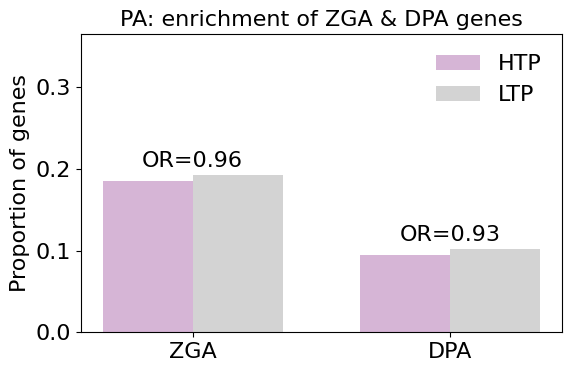

In [10]:
#PA C0,ZGA,DPA
# =========================================================
#PA C0：ZGA / DPA 基因在 TAD strength 随拟时序升高区域中的富集分析
# ---------------------------------------------------------
# 本脚本用于检验：
#   ZGA 基因和发育潜能相关基因（DPA）
# 是否在 TAD strength 随拟时序增加的区域（PA C0 cluster）
# 中显著富集，相对于其他所有区域。
#
# 富集分析采用 Fisher 精确检验，
# 并通过柱状图展示目标区域与其他区域中
# ZGA / DPA 基因所占比例的差异。
# =========================================================


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 16,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 16
})


# ===============================
# 1. 基础函数
# ===============================

def read_gene_list(path):
    """
    读取基因列表文件，返回基因 ID 的集合（set）。

    假设：
    - 每行包含一个基因 ID（或第一列为基因 ID）
    - 使用 set 以保证基因唯一性，并便于集合运算
    """
    genes = []
    with open(path) as f:
        for line in f:
            if line.strip():
                genes.append(line.strip().split()[0])
    return set(genes)


def build_contingency_table(target_genes, other_genes, gene_set):
    """
    构建 Fisher 精确检验所需的 2×2 列联表：

                         gene_set    非 gene_set
    target_genes            a            b
    other_genes             c            d

    其中：
    - target_genes：位于 TAD strength 随拟时序升高区域中的基因
    - other_genes ：位于其余所有区域中的基因
    - gene_set    ：待检验的基因集合（ZGA 或 DPA）
    """
    a = len(target_genes & gene_set)
    b = len(target_genes) - a
    c = len(other_genes & gene_set)
    d = len(other_genes) - c

    table = [[a, b],
             [c, d]]
    return table


def enrichment_stats(target_genes, other_genes, gene_set):
    """
    对给定基因集合（ZGA 或 DPA）计算富集统计量，包括：

    - Fisher 精确检验的优势比（odds ratio）
    - Fisher 精确检验的 p 值
    - gene_set 在目标区域中的比例
    - gene_set 在其他区域中的比例
    """
    table = build_contingency_table(target_genes, other_genes, gene_set)
    or_value, p_value = fisher_exact(table)

    # 目标区域中 gene_set 的比例
    target_prop = table[0][0] / sum(table[0])
    # 其他区域中 gene_set 的比例
    other_prop = table[1][0] / sum(table[1])

    return table, or_value, p_value, target_prop, other_prop


# ===============================
# 2. 读取基因集合
# ===============================

# ZGA 基因列表
ZGA_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/PA_majorZGAid.txt"
)

# DPA（发育潜能相关）基因列表
DPA_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/PA_80_gene_cors_pos_2000.txt"
)

# IVF 中 TAD strength 随拟时序升高（C0 cluster）区域对应的基因
target_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/PA_cluster_0_genes.new.txt"
)

# IVF 中其余区域对应的基因
other_genes = read_gene_list(
    "/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene/PA_cluster_0_genes.non.txt"
)

# 确保目标区域与其他区域的基因集合不重叠
assert len(target_genes & other_genes) == 0


# ===============================
# 3. 富集分析计算
# ===============================

# 待分析的基因集合
gene_sets = {
    "ZGA": ZGA_genes,
    "DPA": DPA_genes
}

results = {}

for label, geneset in gene_sets.items():
    table, or_value, p_value, tp, op = enrichment_stats(
        target_genes, other_genes, geneset
    )
    results[label] = {
        "table": table,
        "odds_ratio": or_value,
        "p_value": p_value,
        "target_prop": tp,
        "other_prop": op
    }

    # 打印列联表和统计结果，便于复现与审查
    print(f"\n[{label}] 列联表：")
    print(pd.DataFrame(
        table,
        index=["TAD strength 升高区域", "其他区域"],
        columns=[label, f"非 {label}"]
    ))
    print(f"优势比 (OR) = {or_value:.3f}")
    print(f"P 值        = {p_value:.3e}")


# ===============================
# 4. 绘制柱状图（升级为 OR 风格）
# ===============================

labels = list(results.keys())
target_props = [results[l]["target_prop"] for l in labels]
other_props = [results[l]["other_prop"] for l in labels]
p_values = [results[l]["p_value"] for l in labels]
or_values = [results[l]["odds_ratio"] for l in labels]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(6, 4))

# IVF target 区域
plt.bar(
    x - width / 2,
    target_props,
    width,
    label="HTP",
    color="#d6b5d6"
)

# IVF background
plt.bar(
    x + width / 2,
    other_props,
    width,
    label="LTP",
    color="lightgrey"
)

plt.ylabel("Proportion of genes")
plt.title("PA: enrichment of ZGA & DPA genes")
plt.xticks(x, labels)

plt.ylim(0, max(target_props + other_props) * 1.9)


# ===== 核心：OR + 显著性 =====
for i in range(len(labels)):
    y = max(target_props[i], other_props[i])

    # OR（主信息）
    plt.text(
        i,
        y + 0.01,
        f"OR={or_values[i]:.2f}",
        ha="center",
        fontsize=16
    )

    # 显著性星号
    p = p_values[i]
    if p <= 0.05:
        if p <= 1e-4:
            star = "****"
        elif p <= 1e-3:
            star = "***"
        elif p <= 1e-2:
            star = "**"
        else:
            star = "*"

        plt.text(
            i,
            y + 0.03,
            star,
            ha="center",
            color="red",
            fontsize=16
        )

plt.legend(frameon=False)
plt.tight_layout()

plt.savefig(
    "PA_HTP_LTP_ZGA_DPA_enrichment_ORstyle.svg",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [2]:
cd /home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene

/home/lihaoxing/PA_IVF_532_25w_TAD/aggregateTADs/TADstrength_vs_Time/TADstrength2Gene



[Boundary enrichment]
Contingency table:
[[307, 1094], [565, 2572]]

cluster_0: 21.9129% (307/1401)
cluster_1: 18.0108% (565/3137)

Odds ratio = 1.277
P-value    = 2.225e-03


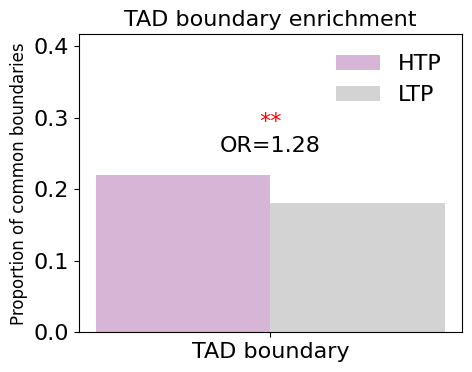

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 1. 输入数据（窗口级）
# =========================
L0 = 1401   # cluster0 total bins
L1 = 3137   # cluster1 total bins

N0 = 307    # cluster0 boundary bins
N1 = 565    # cluster1 boundary bins

# =========================
# 2. 构建列联表
# =========================
table = [
    [N0, L0 - N0],
    [N1, L1 - N1]
]

# =========================
# 3. Fisher 精确检验
# =========================
or_value, p_value = fisher_exact(table)

# density
d0 = N0 / L0
d1 = N1 / L1

print("\n[Boundary enrichment]")
print("Contingency table:")
print(table)

print(f"\ncluster_0: {d0:.4%} ({N0}/{L0})")
print(f"cluster_1: {d1:.4%} ({N1}/{L1})")

print(f"\nOdds ratio = {or_value:.3f}")
print(f"P-value    = {p_value:.3e}")

# =========================
# 4. 可视化
# =========================
labels = ["TAD boundary"]
target_props = [d0]
other_props  = [d1]

plt.figure(figsize=(5, 4))

width = 0.35
x = np.arange(len(labels))

# cluster_0
plt.bar(
    x - width / 2,
    target_props,
    width,
    label="HTP",
    color="#d6b5d6"
)

# cluster_1
plt.bar(
    x + width / 2,
    other_props,
    width,
    label="LTP",
    color="lightgrey"
)

plt.ylabel("Proportion of common boundaries",fontsize=12)
plt.title("TAD boundary enrichment")
plt.xticks(x, labels)

# =========================
# 标注
# =========================
y = max(d0, d1)

plt.text(0, y * 1.15, f"OR={or_value:.2f}", ha="center")

# 显著性星号
if p_value <= 0.05:
    if p_value <= 1e-4:
        star = "****"
    elif p_value <= 1e-3:
        star = "***"
    elif p_value <= 1e-2:
        star = "**"
    else:
        star = "*"

    plt.text(0, y * 1.30, star, ha="center", color="red")

plt.ylim(0, y * 1.9)
plt.legend(frameon=False)

plt.tight_layout()
plt.savefig('TAD_boundary_enrichment.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


[2C]
Contingency table:
[[46, 1355], [124, 3013]]
cluster_0: 3.2834% (46/1401)
cluster_1: 3.9528% (124/3137)
Odds ratio = 0.825
P-value    = 3.099e-01

[4C]
Contingency table:
[[81, 1320], [146, 2991]]
cluster_0: 5.7816% (81/1401)
cluster_1: 4.6541% (146/3137)
Odds ratio = 1.257
P-value    = 1.214e-01


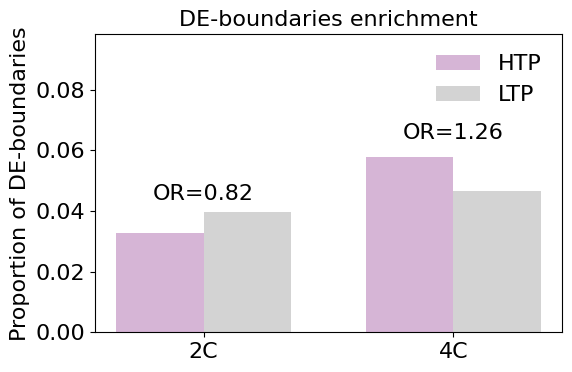

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 1. 输入数据
# =========================
# total windows
L0 = 1401
L1 = 3137

# 2C debin
N0_2C = 46
N1_2C = 124

# 4C debin
N0_4C = 81
N1_4C = 146

# =========================
# 2. Fisher 检验函数
# =========================
def run_fisher(N0, L0, N1, L1, label):
    table = [
        [N0, L0 - N0],
        [N1, L1 - N1]
    ]

    or_value, p_value = fisher_exact(table)

    d0 = N0 / L0
    d1 = N1 / L1

    print(f"\n[{label}]")
    print("Contingency table:")
    print(table)

    print(f"cluster_0: {d0:.4%} ({N0}/{L0})")
    print(f"cluster_1: {d1:.4%} ({N1}/{L1})")

    print(f"Odds ratio = {or_value:.3f}")
    print(f"P-value    = {p_value:.3e}")

    return d0, d1, or_value, p_value


# =========================
# 3. 分别计算 2C / 4C
# =========================
d0_2C, d1_2C, or_2C, p_2C = run_fisher(N0_2C, L0, N1_2C, L1, "2C")
d0_4C, d1_4C, or_4C, p_4C = run_fisher(N0_4C, L0, N1_4C, L1, "4C")


# =========================
# 4. 可视化
# =========================
labels = ["2C", "4C"]

cluster0_vals = [d0_2C, d0_4C]
cluster1_vals = [d1_2C, d1_4C]

plt.figure(figsize=(6, 4))

width = 0.35
x = np.arange(len(labels))

# cluster 0
plt.bar(
    x - width / 2,
    cluster0_vals,
    width,
    label="HTP",
    color="#d6b5d6"
)

# cluster 1
plt.bar(
    x + width / 2,
    cluster1_vals,
    width,
    label="LTP",
    color="lightgrey"
)

plt.ylabel("Proportion of DE-boundaries")
plt.title("DE-boundaries enrichment")
plt.xticks(x, labels)


# =========================
# 5. 标注 OR + 显著性
# =========================
def add_significance(x_pos, d0, d1, or_val, p_val):
    y = max(d0, d1)

    plt.text(x_pos, y * 1.10, f"OR={or_val:.2f}", ha="center")

    if p_val <= 0.05:
        if p_val <= 1e-4:
            star = "****"
        elif p_val <= 1e-3:
            star = "***"
        elif p_val <= 1e-2:
            star = "**"
        else:
            star = "*"

        plt.text(x_pos, y * 1.22, star, ha="center", color="red")


add_significance(x[0], d0_2C, d1_2C, or_2C, p_2C)
add_significance(x[1], d0_4C, d1_4C, or_4C, p_4C)

plt.ylim(0, max(cluster0_vals + cluster1_vals) * 1.7)

plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('DEboundary_enrichment_2C_4C.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


[2C]
Contingency table:
[[115, 1286], [314, 2823]]
cluster_0: 8.2084% (115/1401)
cluster_1: 10.0096% (314/3137)
Odds ratio = 0.804
P-value    = 6.173e-02

[4C]
Contingency table:
[[271, 1130], [636, 2501]]
cluster_0: 19.3433% (271/1401)
cluster_1: 20.2741% (636/3137)
Odds ratio = 0.943
P-value    = 4.946e-01


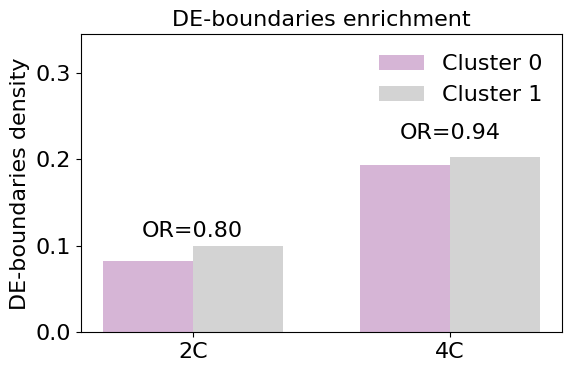

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 1. 输入数据
# =========================
# total windows
L0 = 1401
L1 = 3137

# 2C debin
N0_2C = 115
N1_2C = 314

# 4C debin
N0_4C = 271
N1_4C = 636

# =========================
# 2. Fisher 检验函数
# =========================
def run_fisher(N0, L0, N1, L1, label):
    table = [
        [N0, L0 - N0],
        [N1, L1 - N1]
    ]

    or_value, p_value = fisher_exact(table)

    d0 = N0 / L0
    d1 = N1 / L1

    print(f"\n[{label}]")
    print("Contingency table:")
    print(table)

    print(f"cluster_0: {d0:.4%} ({N0}/{L0})")
    print(f"cluster_1: {d1:.4%} ({N1}/{L1})")

    print(f"Odds ratio = {or_value:.3f}")
    print(f"P-value    = {p_value:.3e}")

    return d0, d1, or_value, p_value


# =========================
# 3. 分别计算 2C / 4C
# =========================
d0_2C, d1_2C, or_2C, p_2C = run_fisher(N0_2C, L0, N1_2C, L1, "2C")
d0_4C, d1_4C, or_4C, p_4C = run_fisher(N0_4C, L0, N1_4C, L1, "4C")


# =========================
# 4. 可视化
# =========================
labels = ["2C", "4C"]

cluster0_vals = [d0_2C, d0_4C]
cluster1_vals = [d1_2C, d1_4C]

plt.figure(figsize=(6, 4))

width = 0.35
x = np.arange(len(labels))

# cluster 0
plt.bar(
    x - width / 2,
    cluster0_vals,
    width,
    label="Cluster 0",
    color="#d6b5d6"
)

# cluster 1
plt.bar(
    x + width / 2,
    cluster1_vals,
    width,
    label="Cluster 1",
    color="lightgrey"
)

plt.ylabel("DE-boundaries density")
plt.title("DE-boundaries enrichment")
plt.xticks(x, labels)


# =========================
# 5. 标注 OR + 显著性
# =========================
def add_significance(x_pos, d0, d1, or_val, p_val):
    y = max(d0, d1)

    plt.text(x_pos, y * 1.10, f"OR={or_val:.2f}", ha="center")

    if p_val <= 0.05:
        if p_val <= 1e-4:
            star = "****"
        elif p_val <= 1e-3:
            star = "***"
        elif p_val <= 1e-2:
            star = "**"
        else:
            star = "*"

        plt.text(x_pos, y * 1.22, star, ha="center", color="red")


add_significance(x[0], d0_2C, d1_2C, or_2C, p_2C)
add_significance(x[1], d0_4C, d1_4C, or_4C, p_4C)

plt.ylim(0, max(cluster0_vals + cluster1_vals) * 1.7)

plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('DEboundary_enrichment_2C_4C.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()


[2C]
Contingency table:
[[506, 895], [1165, 1972]]
cluster_0: 36.1171% (506/1401)
cluster_1: 37.1374% (1165/3137)
Odds ratio = 0.957
P-value    = 5.268e-01

[4C]
Contingency table:
[[716, 685], [1628, 1509]]
cluster_0: 51.1064% (716/1401)
cluster_1: 51.8967% (1628/3137)
Odds ratio = 0.969
P-value    = 6.297e-01


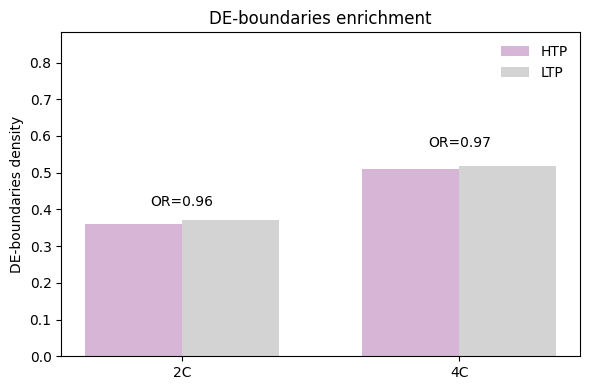

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# =========================
# 1. 输入数据
# =========================
# total windows
L0 = 1401
L1 = 3137

# 2C debin
N0_2C = 506
N1_2C = 1165

# 4C debin
N0_4C = 716
N1_4C = 1628

# =========================
# 2. Fisher 检验函数
# =========================
def run_fisher(N0, L0, N1, L1, label):
    table = [
        [N0, L0 - N0],
        [N1, L1 - N1]
    ]

    or_value, p_value = fisher_exact(table)

    d0 = N0 / L0
    d1 = N1 / L1

    print(f"\n[{label}]")
    print("Contingency table:")
    print(table)

    print(f"cluster_0: {d0:.4%} ({N0}/{L0})")
    print(f"cluster_1: {d1:.4%} ({N1}/{L1})")

    print(f"Odds ratio = {or_value:.3f}")
    print(f"P-value    = {p_value:.3e}")

    return d0, d1, or_value, p_value


# =========================
# 3. 分别计算 2C / 4C
# =========================
d0_2C, d1_2C, or_2C, p_2C = run_fisher(N0_2C, L0, N1_2C, L1, "2C")
d0_4C, d1_4C, or_4C, p_4C = run_fisher(N0_4C, L0, N1_4C, L1, "4C")


# =========================
# 4. 可视化
# =========================
labels = ["2C", "4C"]

cluster0_vals = [d0_2C, d0_4C]
cluster1_vals = [d1_2C, d1_4C]

plt.figure(figsize=(6, 4))

width = 0.35
x = np.arange(len(labels))

# cluster 0
plt.bar(
    x - width / 2,
    cluster0_vals,
    width,
    label="HTP",
    color="#d6b5d6"
)

# cluster 1
plt.bar(
    x + width / 2,
    cluster1_vals,
    width,
    label="LTP",
    color="lightgrey"
)

plt.ylabel("DE-boundaries density")
plt.title("DE-boundaries enrichment")
plt.xticks(x, labels)


# =========================
# 5. 标注 OR + 显著性
# =========================
def add_significance(x_pos, d0, d1, or_val, p_val):
    y = max(d0, d1)

    plt.text(x_pos, y * 1.10, f"OR={or_val:.2f}", ha="center")

    if p_val <= 0.05:
        if p_val <= 1e-4:
            star = "****"
        elif p_val <= 1e-3:
            star = "***"
        elif p_val <= 1e-2:
            star = "**"
        else:
            star = "*"

        plt.text(x_pos, y * 1.22, star, ha="center", color="red")


add_significance(x[0], d0_2C, d1_2C, or_2C, p_2C)
add_significance(x[1], d0_4C, d1_4C, or_4C, p_4C)

plt.ylim(0, max(cluster0_vals + cluster1_vals) * 1.7)

plt.legend(frameon=False)
plt.tight_layout()
plt.savefig('DEboundary_enrichment_2C_4C.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()